In [24]:
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import boxcox



sns.set_theme(style=("whitegrid"), palette="tab10")
warnings.filterwarnings(action="ignore")

In [25]:
df = pd.read_csv("medical_cost.csv")

In [26]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [28]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [29]:
df["region"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

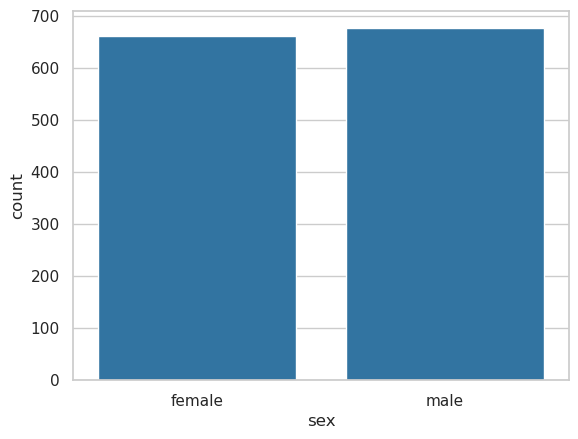

In [30]:
sns.countplot(data=df, x="sex")
plt.show()

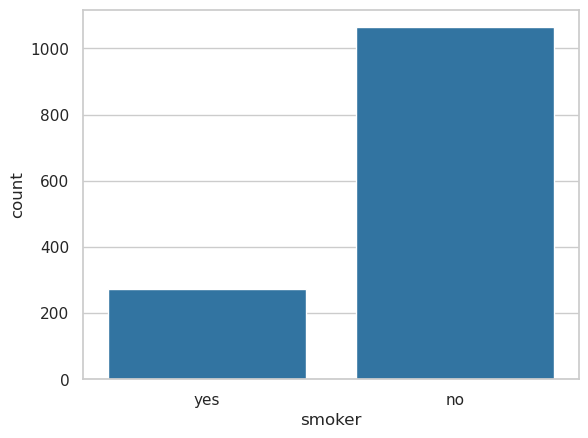

In [31]:
sns.countplot(data=df, x="smoker")
plt.show()

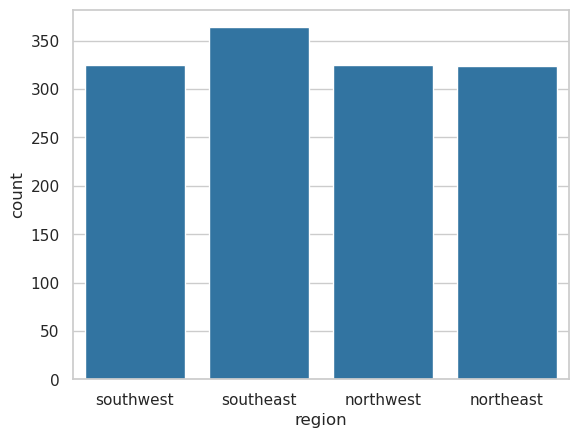

In [32]:
sns.countplot(data=df, x="region")
plt.show()

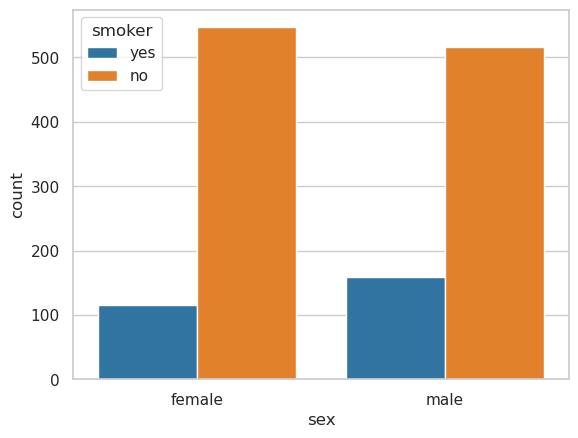

In [33]:
sns.countplot(data=df, x="sex", hue="smoker")
plt.show()

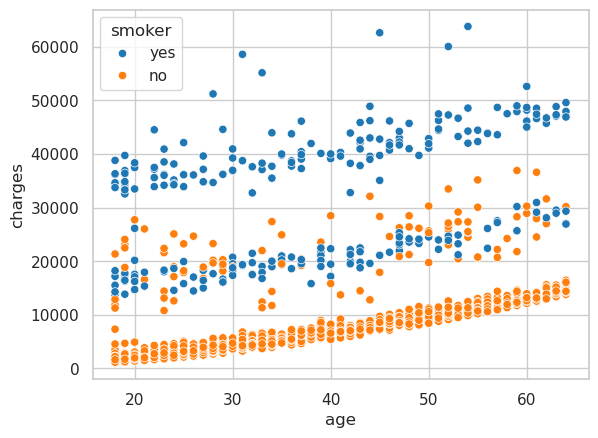

In [34]:
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.show()

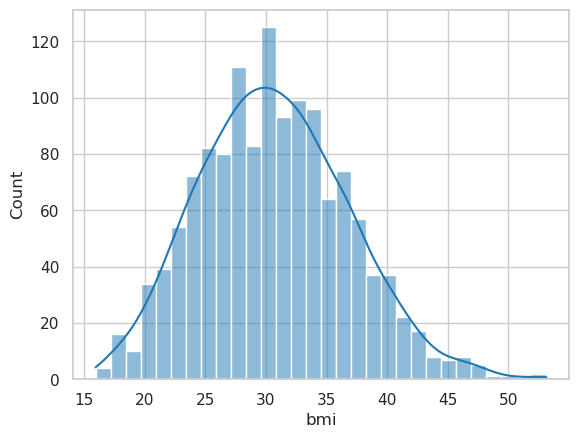

In [35]:
sns.histplot(data=df, x="bmi", kde=True, bins=30)
plt.show()

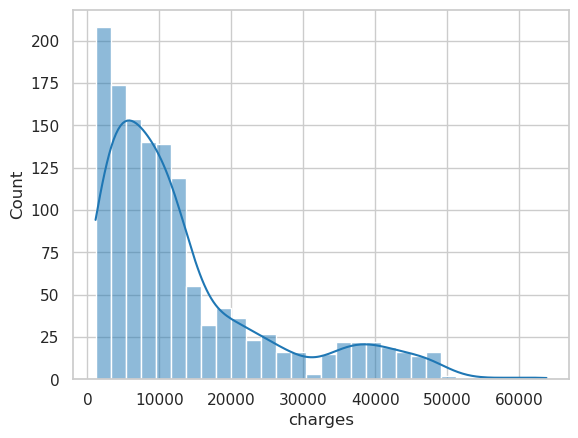

In [36]:
sns.histplot(data=df, x="charges", kde=True, bins=30)
plt.show()

In [37]:
# Dependent Feature ne kadar normal dagilima yakinsa model okadar daha iyi performans gosterir.

In [38]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [39]:
df["sex"] = df["sex"].map({"male": 1, "female" : 0})

In [40]:
df["smoker"] = df["smoker"].map({"yes" : 1, "no" : 0})

In [41]:
df["region"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [61]:
X = df.drop("charges", axis=1)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=15)

In [62]:
categorical_cols = ["region"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_cols)
    ], 
    remainder="passthrough"
)

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

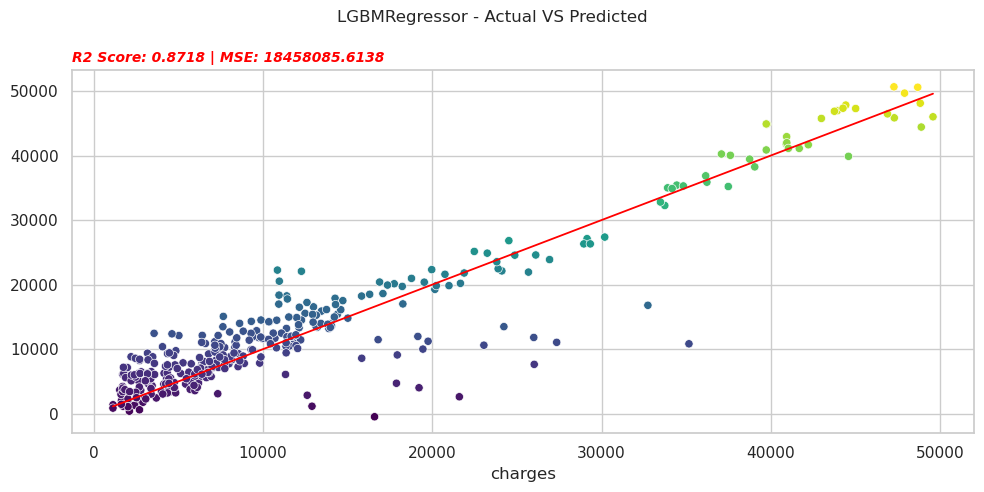

In [67]:
pipe = Pipeline([
    ("model", LGBMRegressor(verbosity=-1))
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


plt.figure(figsize=(10,5))
sns.scatterplot( 
    x=y_test, 
    y=y_pred,
    legend=False,
    hue=y_pred,
    palette="viridis"
)
plt.suptitle("LGBMRegressor - Actual VS Predicted", fontsize=12)

plt.title(f"R2 Score: {r2:.4f} | MSE: {mse:.4f}", loc="left", style="italic", fontsize=10, fontweight="bold", color="r")
plt.plot([y_test.min(),y_test.max()], [y_test.min(), y_test.max()], linewidth=1.3, color="r")

plt.tight_layout()
plt.show()

/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


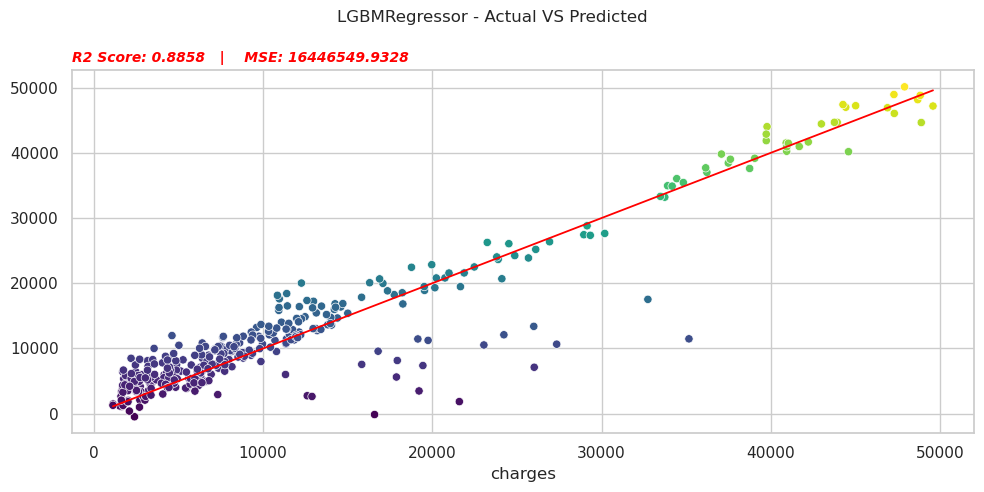

,Parameters,Values
0,model__subsample,0.6
1,model__reg_lambda,1.0
2,model__reg_alpha,0.5
3,model__num_leaves,50.0
4,model__n_estimators,100.0
5,model__min_child_samples,30.0
6,model__max_depth,-1.0
7,model__learning_rate,0.1
8,model__colsample_bytree,0.8


In [78]:
params = {
    "model__learning_rate" : [0.01, 0.05, 0.1],
    "model__n_estimators" : [100, 300, 1000],
    "model__max_depth" : [-1, 5, 10], # max_depth (int, optional (default=-1)) -> limit yok demek
    "model__num_leaves" : [31, 50, 70],
    "model__min_child_samples" : [10, 20, 30],
    "model__subsample" : [0.6, 0.8, 1.0],
    "model__colsample_bytree" : [0.6, 0.8, 1.0],
    "model__reg_alpha" : [0, 0.5, 1.0],
    "model__reg_lambda" : [0, 0.5, 1.0]
}

rscv = RandomizedSearchCV(
    pipe,
    param_distributions=params,
    scoring="neg_root_mean_squared_error",
    random_state=15,
    verbose=-1,
    cv=5,
    n_jobs=-1
)

rscv.fit(X_train, y_train)
y_pred1 = rscv.predict(X_test)


mse = mean_squared_error(y_test, y_pred1)
r2 = r2_score(y_test, y_pred1)


plt.figure(figsize=(10,5))
sns.scatterplot( 
    x=y_test, 
    y=y_pred1,
    legend=False,
    hue=y_pred1,
    palette="viridis"
)
plt.suptitle("LGBMRegressor - Actual VS Predicted", fontsize=12)

plt.title(f"R2 Score: {r2:.4f}   |    MSE: {mse:.4f}", loc="left", style="italic", fontsize=10, fontweight="bold", color="r")
plt.plot([y_test.min(),y_test.max()], [y_test.min(), y_test.max()], linewidth=1.3, color="r")

plt.tight_layout()
plt.show()

pd.DataFrame(rscv.best_params_.items(), columns=["Parameters", "Values"])

In [69]:
# let's try with transformations on the dependent feature

In [71]:
y_train_transformed, lambda_y = boxcox(y_train)

pipe.fit(X_train, y_train_transformed)
y_pred_tranformed = pipe.predict(X_test) 

In [72]:
def inverse_boxcox(y, lambda_):
    if lambda_ == 0:
        return np.exp(y) # e si alinir.

    else:
        return np.power(y * lambda_ + 1, 1 / lambda_)

In [73]:
y_pred_original = inverse_boxcox(y_pred_tranformed, lambda_y)

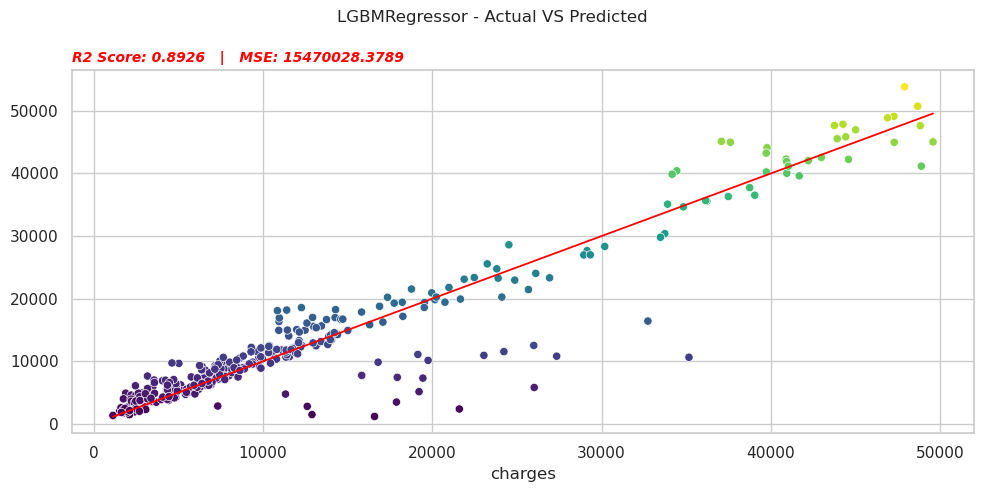

,Parameters,Values
0,model__subsample,0.6
1,model__reg_lambda,1.0
2,model__reg_alpha,0.5
3,model__num_leaves,50.0
4,model__n_estimators,100.0
5,model__min_child_samples,30.0
6,model__max_depth,-1.0
7,model__learning_rate,0.1
8,model__colsample_bytree,0.8


In [79]:
mse = mean_squared_error(y_test, y_pred_original)
r2 = r2_score(y_test, y_pred_original)


plt.figure(figsize=(10,5))
sns.scatterplot( 
    x=y_test, 
    y=y_pred_original,
    legend=False,
    hue=y_pred_original,
    palette="viridis"
)
plt.suptitle("LGBMRegressor - Actual VS Predicted", fontsize=12)

plt.title(f"R2 Score: {r2:.4f}   |   MSE: {mse:.4f}", loc="left", style="italic", fontsize=10, fontweight="bold", color="r")
plt.plot([y_test.min(),y_test.max()], [y_test.min(), y_test.max()], linewidth=1.3, color="r")

plt.tight_layout()
plt.show()

pd.DataFrame(rscv.best_params_.items(), columns=["Parameters", "Values"])